In [1]:
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd

from my_utils import *

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']

from ana_functions import *

In [2]:
def rotate_array(l,x):
    return np.concatenate((l[-x:],l[:-x]),axis=0)

In [3]:
file_path = '20260814_1007_scifi_all_channels.csv'

period = 1/150e6

In [4]:
##################################################
##                 read in data                 ##
##################################################



# Format: ignore first line (until \n), nothing to parse here! 
# Then: WS-separated [\n ]* list of 
# [CHANNEL NUMBER] [COARSETIME, 19 bit] [INTERMEDIATE TIME] [FINE TDL 0101010]


# fine TDL has a length of 77
# on and off phaseses are around 32 bits long


# Replace 'your_file.txt' with the path to your ASCII file
# file_path = '20260611_0658_scifi_128ch_hitflag_at_m5_itime_20.csv'

# Read the first 1000 lines of the whitespace-separated file into a DataFrame
#df = pd.read_csv(file_path, delim_whitespace=True, nrows=10000, skiprows = 1, header=None)
#df = pd.read_csv(file_path, delim_whitespace=False, nrows=100000, dtype={'fine':str, 'interm':str})
#df = pd.read_csv(file_path, delim_whitespace=False, nrows=int(.1e6), dtype={'fine':str, 'interm':str})
df = pd.read_csv(file_path, delim_whitespace=False, nrows=int(100e6), dtype={'fine':str, 'interm':str})
#df = pd.read_csv(file_path, delim_whitespace=True, skiprows = 1, header=None)

# Display the DataFrame
df[0:10]

,trig_num,trig_time,chan,coarse,falling,fine,itime,i,q
0,6988786,25421014903366,0,290,0,1111111111100000000011111111111111111111111111...,4,-26,-19
1,6988786,25421014903366,0,287,1,1111111111111100000000000000000000001111111111...,6,-20,13
2,6988786,25421014903366,1,290,0,1111111100000000000011111111111111111111111111...,3,-19,-26
3,6988786,25421014903366,1,287,1,1111111111111000000000001111111111111111111111...,5,-29,-12
4,6988786,25421014903366,2,290,0,1111111111000000000000000000000000000000000000...,4,3,26
5,6988786,25421014903366,2,287,1,1111111111111000000000000000000000000000000000...,5,12,29
6,6988786,25421014903366,3,290,0,1111111110000000000011110000000000000000000000...,3,29,8
7,6988786,25421014903366,3,287,1,1111111111111000000011111100000000000000000000...,5,28,5
8,6988786,25421014903366,4,290,0,1111111110000000000011111111111100000000000000...,3,21,-8
9,6988786,25421014903366,4,287,1,1111111111110000000000000000111111111111111111...,5,-29,-4


In [5]:
## active channels
active_channels = df["chan"].unique()

active_channels

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127])

In [6]:

chan_a = 66

itime_len = 20
ftime_len = 80



def process_channel(df,chan,**kwargs):
    
    # the output object
    output = {}

    
    
    plot = kwargs.get("plot",False)
    
    ##################################################
    ##                data selection                ##
    ##################################################


    df_a = df[ (df["chan"] == chan) & (df["falling"] == 0) ]



    ctime_a = np.array(df_a["coarse"])

    itime_a = np.array( [ pop_count(x[0:itime_len]) for x in df_a["fine"] ])

    tdl_a = [ x[itime_len:itime_len+ftime_len][::-1] for x in df_a["fine"] ]


    ##################################################
    ##              calc IQ population              ##
    ##################################################

    avail_TDL=80
    period = int(avail_TDL/1.25)
    # the real period
    #period = 80

    # length for a single IQ pair = period * 3/4  (period/2 + period/4)
    # length for a double IQ pair = period * 5/4  (period   + period/4)

    #    |--------period--------|
    #
    # .../***********\........../***********\........../
    # 
    # |----I1----||----I2----|
    #       |----Q1----||----Q2----|
    # |---------avail. TDL---------|
    #
    #

    iqlen = int(period/2)
    #iqlen = 31

    istart = 0
    qstart = istart + int(period/4)
    #qstart = istart + 17


    I_a, Q_a, = calc_IQ(istart,qstart,iqlen,tdl_a)

    ab_offset = int(period/2)

    I_b, Q_b, = calc_IQ(ab_offset+istart,ab_offset+qstart,iqlen,tdl_a)

    I_ab = I_a - I_b
    Q_ab = Q_a - Q_b

    
    if(plot):

        small_figure()

        plt.scatter(I_a,Q_a,s=2,label="IQ_a")
        plt.legend()
        plt.show()

        plt.scatter(I_b,Q_b,s=2,label="IQ_b",color=colors[2])
        plt.legend()
        plt.show()

        plt.scatter(I_ab,Q_ab,s=2,label="IQ_(a-b)")
        plt.legend()
        plt.show()
        
    ##################################################
    ##              analyze rotations               ##
    ##################################################
    
    rotations_a, gap_centers_a = ana_rot(I_ab,Q_ab,np.floor(itime_a/1),plot=plot)
    
    output["rotations"]   = rotations_a
    output["gap_centers"] = gap_centers_a

    ##################################################
    ##                  unfold phi                  ##
    ##################################################
    
    cphi_a = cont_phi_new(I_ab,Q_ab,np.floor(itime_a/1),rotations_a,gap_centers_a)

    phistep = 0.01
    phirange = 60

    x, box_diagram = fast_hist(cphi_a,0,phirange,phistep)
    #plt.bar(x,ya)
    
    ##################################################
    ##              calibration curve               ##
    ##################################################

    calib_bins = x

    calib_curve = np.cumsum(box_diagram)/np.sum(box_diagram)

    if (plot):
        plt.title("calibration curve")
        plt.plot(calib_bins,calib_curve,label="tdc chan 0")
        plt.legend()
        plt.xlabel("phi(rad)")
        plt.ylabel("fraction of coarse period")
        plt.show()
        
    output["calib_bins"]  = calib_bins
    output["box_diagram"] = box_diagram
    output["calib_curve"] = calib_curve
    
    
    ## alternative more truthful calib curve
    ## attributing the time values to the center of the phi bins
    
    #box_cor = rotate_array(box_diagram.copy(),-1)
    #last_val = box_cor[len(box_cor)-1]
    #for i in range(len(box_cor)-2,0-1,-1):
    #    if (box_cor[i] == 0):
    #        box_cor[i] = last_val
    #    else:
    #        last_val = box_cor[i]
    #        
    #calib_curve = (np.cumsum(box_diagram) + 0.5*box_cor )/np.sum(box_diagram)
    #output["calib_curve"] = calib_curve
        
    ##################################################
    ##                  calibrate                   ##
    ##################################################


    period = 1./150e6 # 150 MHz

    ftime_a = calib_ftime(cphi_a,calib_curve,phistep,period)

    #time_a = np.floor(ctime_a/2) * period - ftime_a
    time_a = np.floor(ctime_a) * period - ftime_a
    
    output["t_lead"] = time_a
    
    
    ##################################################
    ##                  bin sizes                   ##
    ##################################################
    
    bin_prob = box_diagram/np.sum(box_diagram)
    bin_sizes = bin_prob * period
    avg_bin_size = np.dot(bin_prob,bin_sizes)
    
    output["avg_bin_size"] = avg_bin_size
    
    
    ##################################################
    ##                 self_lookup                  ##
    ##################################################

    entries = np.sum(box_diagram)
    cumsum  = np.cumsum(box_diagram)
    self_lookup = np.zeros(int(entries))

    c = 0
    for i in range(0,len(box_diagram)):
        bin_content = box_diagram[i]
        d = c
        for j in range(0,int(bin_content)):
            self_lookup[c] = d
            c += 1
    output["self_lookup"] = self_lookup
    
    ##################################################
    ##                return output                 ##
    ##################################################
    
    return output



In [7]:
ch_data = {}

for i in active_channels:
    ch_data[i] =  process_channel(df,i,plot=False)

In [8]:
# little monte carlo for testing measurement precision of ch a vs ch b


def sim_stddev_MC(ch_a,ch_b,n,**kwargs):
    
    meas = np.zeros(n)

    self_lookup_a = ch_data[ch_a]["self_lookup"]
    entries_a = len(self_lookup_a)

    self_lookup_b = ch_data[ch_b]["self_lookup"]
    entries_b = len(self_lookup_b)

    # shift between channels
    shift = kwargs.get("shift",0)
    
    rand_shift = kwargs.get("rand_shift",False)


    for i in range(n):
        ra = np.random.random()
        if rand_shift:
            shift = np.random.random()
        rb = (ra +shift)%1.0
        meas_a = ra - (1/entries_a * self_lookup_a[int(entries_a*ra)])
        meas_b = rb - (1/entries_b * self_lookup_b[int(entries_b*rb)])
        meas[i] = meas_a - meas_b

    stddev = np.std(meas)*period
    
    return stddev
    


In [9]:
# little monte carlo for testing measurement precision of a single channel
# vs the real time

def sim_stddev_MC_single(ch_a,n):

    self_lookup_a = ch_data[ch_a]["self_lookup"]
    entries_a = len(self_lookup_a)

    meas = np.zeros(n)
    for i in range(n):
        r = np.random.random()
        meas[i] = r - (1/entries_a * self_lookup_a[int(entries_a*r)]) 

    return np.std(meas) * period

Text(0.5,1,'MC stddev of ch against itself but with shift')

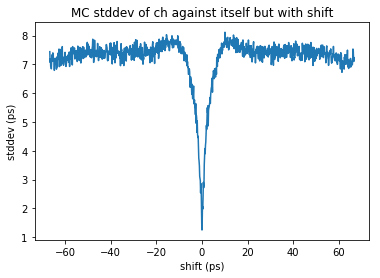

In [10]:
shift = np.linspace(-0.01,.01,1000)
my_MC_stddev = np.array([ sim_stddev_MC(64,64,1000,shift=s) for s in shift ])
plt.plot(shift*period*1e12,my_MC_stddev*1e12)
plt.xlabel("shift (ps)")
plt.ylabel("stddev (ps)")
plt.title("MC stddev of ch against itself but with shift")

In [11]:
ch_data[64]

{'rotations': array([ 0.,  0.,  0.,  0.,  0.,  1.,  1.,  2.,  2.,  2.,  3.,  3.,  3.,
         4.,  4.,  5.,  5.,  5.,  6.]),
 'gap_centers': array([  0.00000000e+00,   0.00000000e+00,   0.00000000e+00,
          0.00000000e+00,   0.00000000e+00,  -1.21966786e+00,
          1.17809725e+00,  -3.05901831e+00,  -5.80334493e-01,
          2.25085993e+00,  -1.57728947e+00,   4.32887363e-01,
          2.72779709e+00,  -7.89730811e-01,   1.83724377e+00,
         -2.39610948e+00,   1.47928562e-03,   2.77124289e+00,
         -1.56043512e+00]),
 'calib_bins': array([  0.00000000e+00,   1.00000000e-02,   2.00000000e-02, ...,
          5.99700000e+01,   5.99800000e+01,   5.99900000e+01]),
 'box_diagram': array([ 0.,  0.,  0., ...,  0.,  0.,  0.]),
 'calib_curve': array([ 0.,  0.,  0., ...,  1.,  1.,  1.]),
 't_lead': array([  1.93244814e-06,   1.93683996e-06,   1.93241564e-06, ...,
          1.93154957e-06,   1.93055895e-06,   1.93439442e-06]),
 'avg_bin_size': 1.2689206316783058e-11,
 'self_looku

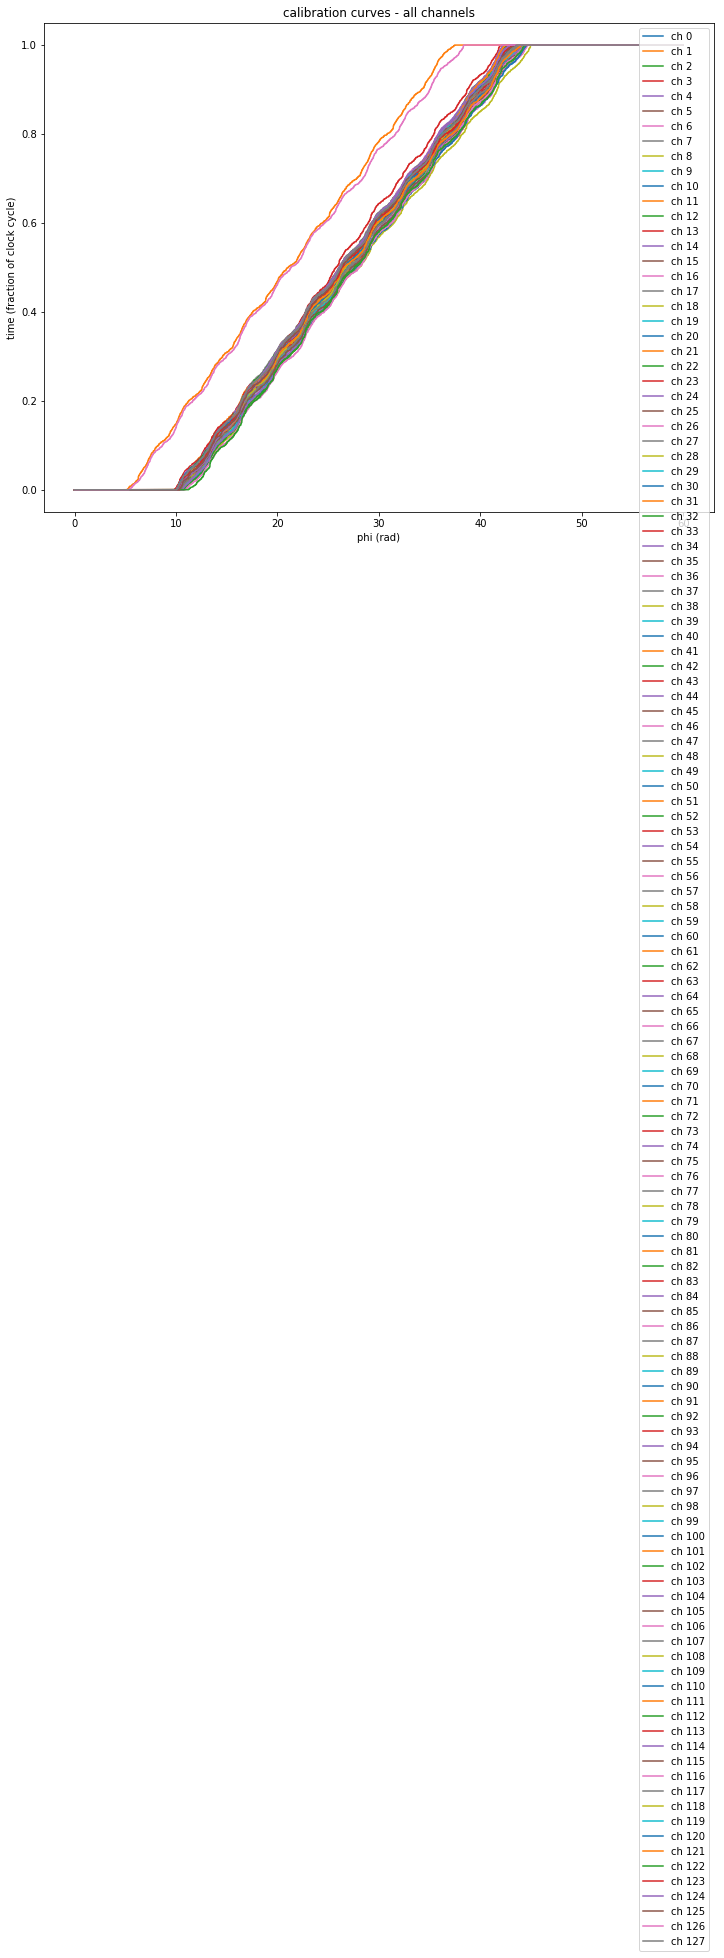

In [12]:
big_figure()

for key in ch_data.keys():
    d = ch_data[key]
    x = d["calib_bins"]
    y = d["calib_curve"]
    plt.plot(x,y,label="ch "+str(key))
    
plt.title("calibration curves - all channels")
plt.xlabel("phi (rad)")
plt.ylabel("time (fraction of clock cycle)")
plt.legend()
plt.show()


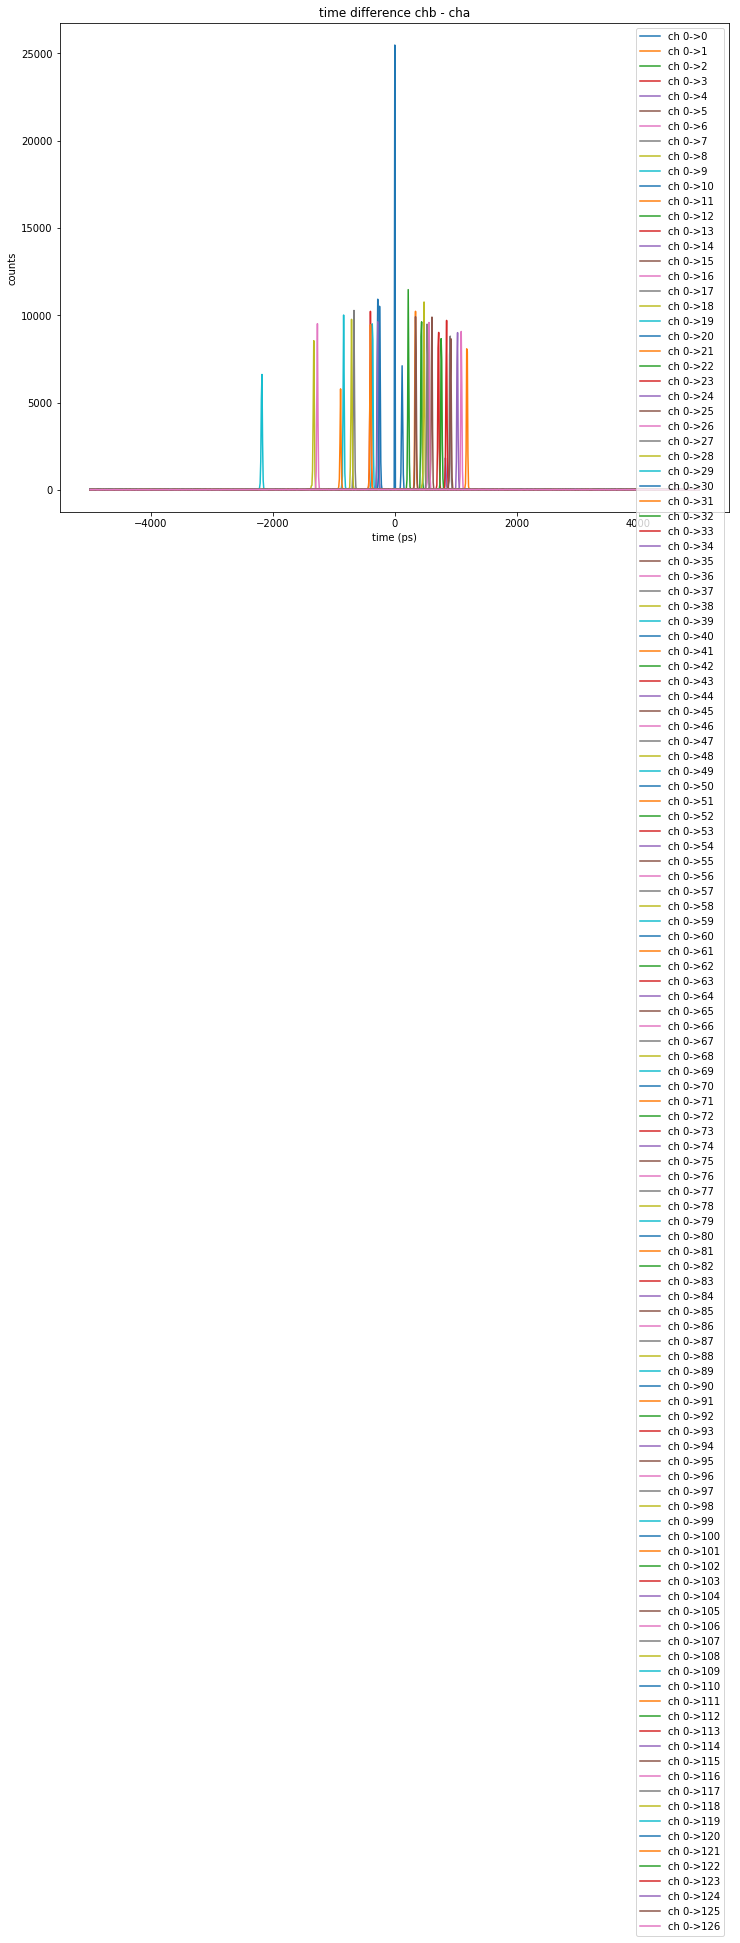

In [14]:

na = 0
#nb = 65

L = -5e-9
R = 5e-9

ch_ch_dev     = np.array([0.0]*128)
avg_bin_sizes = np.array([0.0]*128)
prec_vs_na    = np.array([0.0]*128)

MC_std_vs_na   = np.array([0.0]*128) 
MC_std_vs_self = np.array([0.0]*128) 
MC_std_vs_ideal = np.array([0.0]*128) 

for nb in range(0,127):


    time_a = ch_data[na]["t_lead"]
    time_b = ch_data[nb]["t_lead"]

    nevents = np.min([len(time_a),len(time_b)])

    tdiff = time_b[0:nevents] - time_a[0:nevents]

    mask = (tdiff > L) & (tdiff < R)
    tdiff = tdiff[mask]

    #plt.hist(tdiff*1e12,bins = np.arange(-2500,2500,10))
    x,y = fast_hist(tdiff*1e12,L*1e12,R*1e12,10)
    plt.plot(x,y,label="ch {}->{}".format(na,nb))
    std = np.std(tdiff)
    if(0):
        print("ch {} vs ch {}".format(na,nb))
        print("standard deviation: {:3.3f}ps".format(std*1e12))
        print("mean diff: {:3.3f}ns".format(np.mean(tdiff)*1e9))
    
    ch_ch_dev[nb] = std
    
    avg_bin_sizes[nb] = ch_data[nb]["avg_bin_size"]
    
    prec_vs_na[nb] = np.sqrt( (avg_bin_sizes[nb] *1/np.sqrt(12))**2 + (avg_bin_sizes[na] *1/np.sqrt(12))**2   )

    
    MC_std_vs_na[nb]  = sim_stddev_MC(na,nb,1000)
    MC_std_vs_self[nb]  = sim_stddev_MC(nb,nb,1000,rand_shift=True)
    MC_std_vs_ideal[nb]  = sim_stddev_MC_single(nb,1000)
    
    


#plt.hist(tdiff*1e12)
plt.title("time difference chb - cha")
plt.legend()
plt.ylabel("counts")
plt.xlabel("time (ps)")
plt.show()





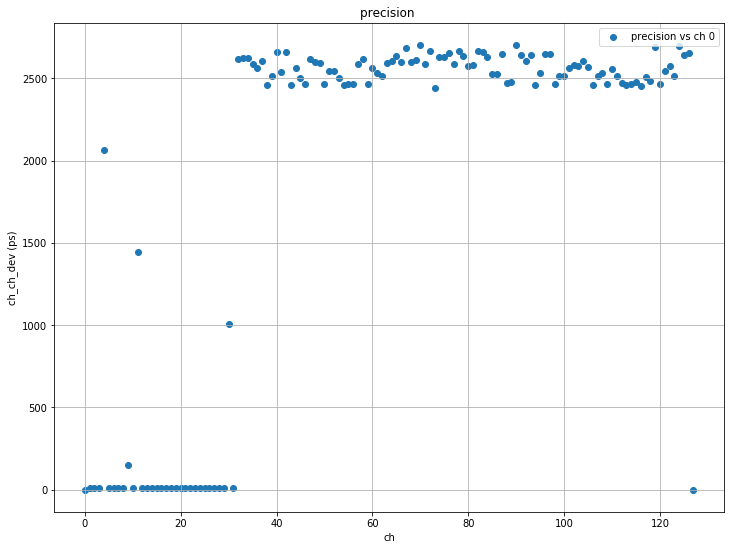

In [16]:
x = np.array(range(0,len(ch_ch_dev)))
#plt.plot(x,ch_ch_dev*1e12)
plt.scatter(x,ch_ch_dev*1e12,label="precision vs ch {}".format(na))

#new = ch_ch_dev.copy()
#plt.scatter(x,new*1e12,label="new".format(na))

plt.xlabel("ch")
plt.ylabel("ch_ch_dev (ps)")
#plt.xlim(60,100)
plt.grid(True)
plt.title("precision ")
plt.legend()
plt.show()


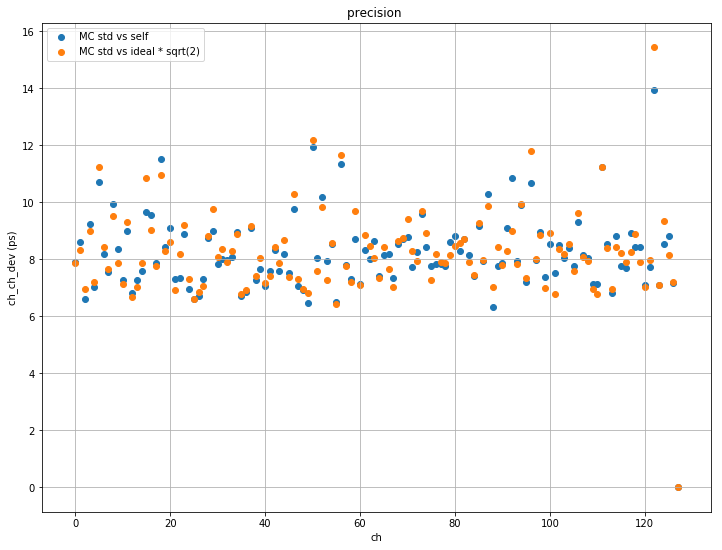

In [20]:
x = np.array(range(0,len(ch_ch_dev)))
#plt.plot(x,ch_ch_dev*1e12)


#plt.scatter(x,ch_ch_dev*1e12,label="precision vs ch 64")

#plt.scatter(x,avg_bin_sizes*1e12,label="avg_bin_size")

#TDC bin error is not 1/sqrt(12) but 1/sqrt(3) - because we do not round

#plt.scatter(x,prec_vs_na*1e12,label="gauss ch vs ch 64")

#plt.scatter(x,MC_std_vs_na*1e12,label="MC std vs ch{}".format(na))
plt.scatter(x,MC_std_vs_self*1e12,label="MC std vs self")
#plt.scatter(x,MC_std_vs_ideal*1e12,label="MC std vs ideal")
plt.scatter(x,MC_std_vs_ideal*1e12*np.sqrt(2),label="MC std vs ideal * sqrt(2)")
#plt.scatter(x,avg_bin_sizes/np.sqrt(3)*1e12,label="avg_bin_size/sqrt3")
#plt.scatter(x,avg_bin_sizes/np.sqrt(12)*1e12,label="avg_bin_size/sqrt12")

plt.xlabel("ch")
plt.ylabel("ch_ch_dev (ps)")
#plt.xlim(60,100)
plt.grid(True)
plt.title("precision ")
plt.legend()
plt.show()


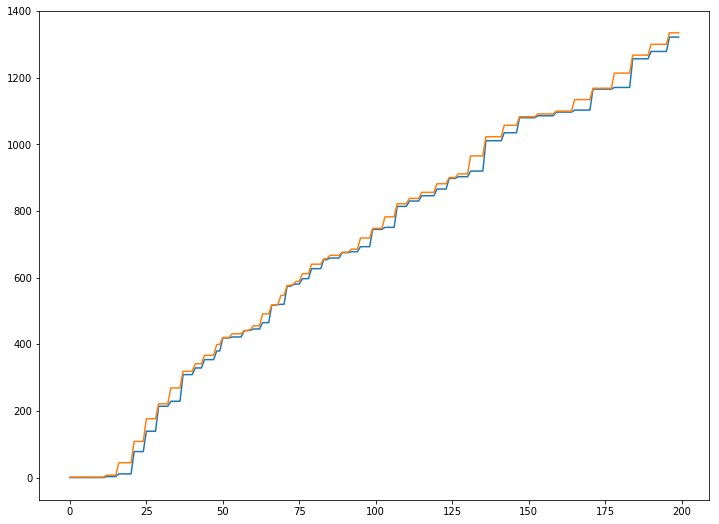

In [21]:
ccurve = ch_data[64]["calib_curve"]
box    = ch_data[64]["box_diagram"]
csum   = np.cumsum(box)

#plt.plot(ccurve[1000:1200])
plt.plot(csum[1000:1200])

box_cor = rotate_array(box.copy(),-1)



last_val = box_cor[len(box_cor)-1]
for i in range(len(box_cor)-2,0-1,-1):
    if (box_cor[i] == 0):
        box_cor[i] = last_val
    else:
        last_val = box_cor[i]
        
        
#plt.plot(10*box[1000:1200])
#plt.plot(10*box_cor[1000:1200])
plt.plot(csum[1000:1200]+.5*box_cor[1000:1200])

#plt.plot

     